['VQAAQAGDTKPIEV', 'aQAAQAGDTKPIEV', 'VaAAQAGDTKPIEV', 'VQAAaAGDTKPIEV', 'VQAAQAaDTKPIEV', 'VQAAQAGaTKPIEV', 'VQAAQAGDaKPIEV', 'VQAAQAGDTaPIEV', 'VQAAQAGDTKaIEV', 'VQAAQAGDTKPaEV', 'VQAAQAGDTKPIaV', 'VQAAQAGDTKPIEa']


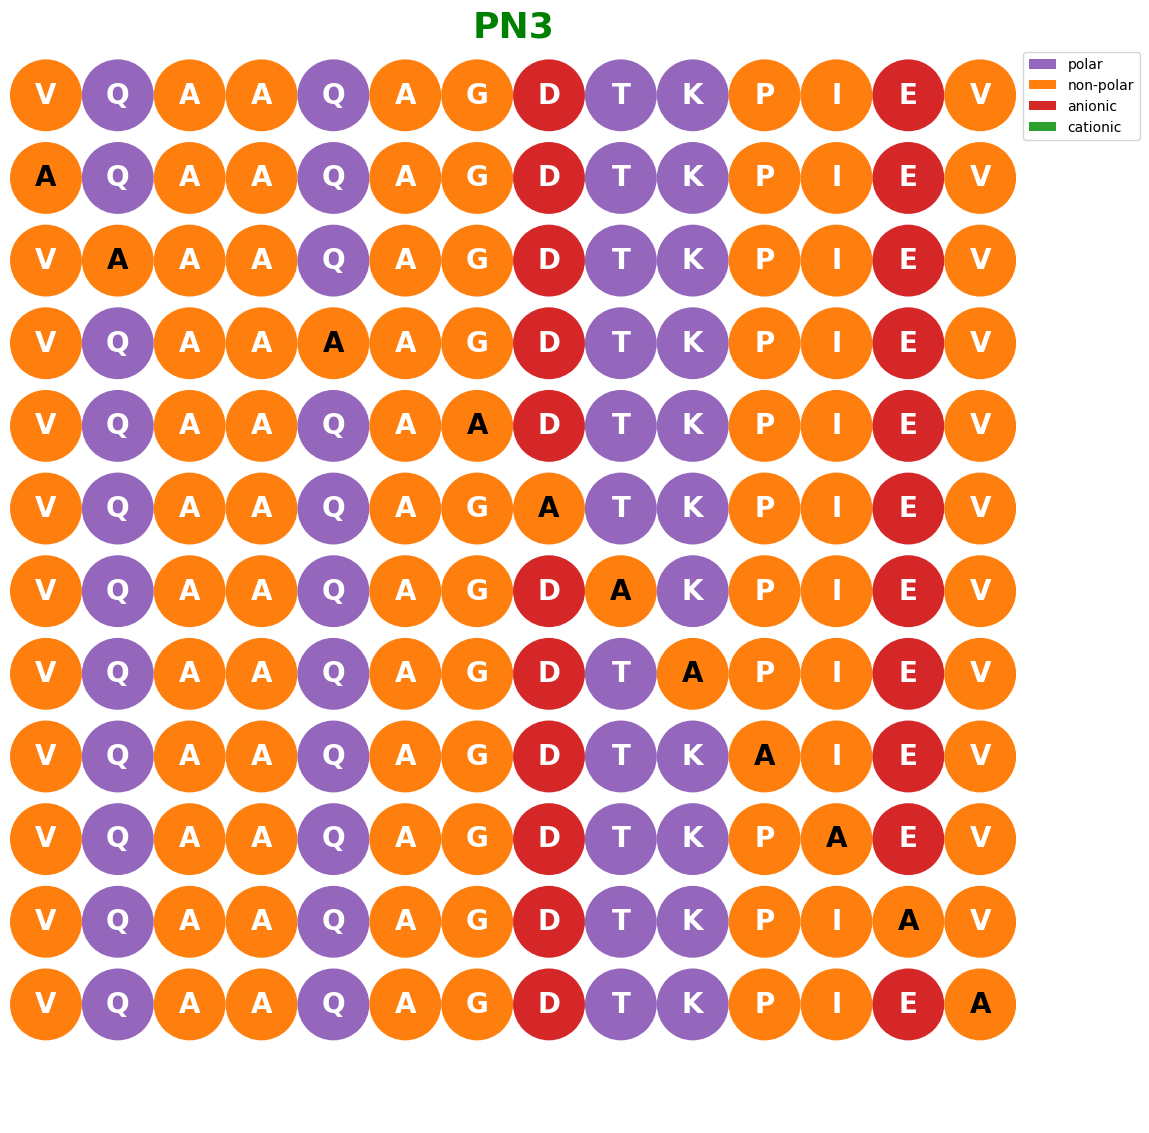

<Figure size 640x480 with 0 Axes>

In [18]:
import matplotlib.pyplot as plt
import numpy as np

# Define the original sequence
#original_sequence = "PDEAK" 

original_sequence = "VQAAQAGDTKPIEV" #PN3
#original_sequence = "VTDTSGKAGTTKISNV" #PN5


# Define the amino acid categories
amino_acid_categories = {
    'polar': ['N', 'C', 'Q', 'K', 'S', 'T', 'Y'],
    'non-polar': ['A', 'V', 'L', 'I', 'M', 'F', 'P', 'G', 'W'],
    'anionic': ['D', 'E'],
    'cationic': ['R', 'H', 'K']
}


# Define the color map for different amino acid categories
color_map = {
    'polar': '#9467bd',         # Purple
    'non-polar': '#ff7f0e',      # Orange
    'anionic': '#d62728',        # Red
    'cationic': '#2ca02c'        # Green
}

# Create a matrix to store the modified sequences
matrix = np.zeros((len(original_sequence), len(original_sequence)), dtype=object)

# Iterate over each position in the sequence
for i in range(len(original_sequence)):
    # Create a copy of the original sequence
    new_sequence = list(original_sequence)

    # Replace the amino acid at position i with alanine
    if new_sequence[i] != "A":
        new_sequence[i] = "a"
    # Store the modified sequence in the matrix
    matrix[i] = new_sequence

# Print the matrix of modified sequences
Ala_scan_seq = []

# Add the original sequence at the beginning
Ala_scan_seq.append(original_sequence)

for row in matrix:
    modified_peptide = ''.join(row)
    if modified_peptide != original_sequence:
        Ala_scan_seq.append(modified_peptide)

# Print the Ala_scan_seq list
print(Ala_scan_seq)

from matplotlib.patches import Patch

# Create a legend for the color representation
legend_elements = [
    Patch(facecolor=color_map['polar'], edgecolor='black', label='Polar'),
    Patch(facecolor=color_map['non-polar'], edgecolor='black', label='Non-polar'),
    Patch(facecolor=color_map['anionic'], edgecolor='black', label='Anionic'),
    Patch(facecolor=color_map['cationic'], edgecolor='black', label='Cationic')
]

# Calculate the maximum sequence length
max_length = max(len(seq) for seq in Ala_scan_seq)

# Create a list to store the circle objects
circles = []

# Iterate over the amino acid sequences
for i, seq in enumerate(Ala_scan_seq):
    for j, aa in enumerate(seq):
        # Calculate the x and y positions based on the index
        #x = (j + 0.5) / (max_length + 2.5)
        #y = 1 - (i + 1) / (len(Ala_scan_seq) + 1.5)
        
        x = (j + 1.5) #/ (len(seq) + 25)
        y = len(Ala_scan_seq) - (i)#/ (len(Ala_scan_seq) + 20)
        
          # Adjust the vertical spacing between the sequences
        y_spacing = 1.15  # Adjust this value to change the vertical spacing
        y = y * y_spacing
       

        # Calculate the radius based on the grid size
        #Radius of 0.5 will touch each other
        radius = 0.5 # / max(max_length, len(Ala_scan_seq))

        # Get the category of the amino acid
        category = None
        for key, values in amino_acid_categories.items():
            if aa in values:
                category = key
                break

        # Skip the amino acid if no category is found
        if category is None:
            if aa == 'a':
                category = 'non-polar'

        # Get the color for the category
        color = color_map[category]

        # Create the circle object
        circle = plt.Circle((x, y), radius, facecolor=color, label=aa)

        # Add the circle to the list
        circles.append(circle)

# Sort the circles based on radius in descending order
circles.sort(key=lambda c: c.radius, reverse=True)

# Create the figure and axes
#fig, ax = plt.subplots(figsize=(max_length / 2, len(Ala_scan_seq) / 2))
seq_max_length = max(len(seq) for seq in Ala_scan_seq)
ala_seq_length = len(Ala_scan_seq)

fig, ax = plt.subplots(figsize=(max_length+3.5, ala_seq_length+2))


# Add the circles to the plot in the desired order
for circle in circles:
    ax.add_artist(circle)
    # Add the amino acid letter as text inside the circle
    aa = circle.get_label()
    if aa == 'a':
        ax.text(circle.center[0], circle.center[1], f"{aa.capitalize()}", color='black', va='center', ha='center', fontsize=20
                , weight='bold')
    else:
        ax.text(circle.center[0], circle.center[1], f"{aa}", color='white', va='center', ha='center', fontsize=20, weight='bold')

# Set the x-axis limits
#plt.xlim(-0.01, max_length / (max_length + 2))

# Set the y-axis limits
#plt.ylim(0.02, 1)

y_padding = 0.5  # Adjust this value to add padding at the top and bottom
y_min = -y_padding
y_max = 0.2+len(Ala_scan_seq) * y_spacing + y_padding

plt.xlim(1, seq_max_length+1)
#plt.ylim(-y_padding, ala_seq_length +1 * 2)
plt.ylim(y_min, y_max)

# Create the color legend
legend_elements = [Patch(facecolor=color, edgecolor='none', label=category) for category, color in color_map.items()]
legend = ax.legend(handles=legend_elements, loc='best', bbox_to_anchor=(1, 1))

# Set the background color of the legend
legend.get_frame().set_facecolor('white')

# Set the aspect ratio to equal
ax.set_aspect('equal')



# Show the plot
ax.axis("off")
ax.grid("off");
plt.title('PN3',color = "green", fontsize = 26, weight = "bold")
plt.show()
plt.savefig("PN3_Ala_scan.tif",dpi = 600, format = "tif")
